In [ ]:
import pandas as pd

# 1. Cargar el archivo de Excel
nombre_archivo = 'BASE _DATOS_COMPILADA.xlsx'

try:
    df = pd.read_excel(nombre_archivo)
    print("¡Archivo cargado correctamente!")

    # 2. Renombrar las columnas de tu Excel real a las que el script necesita
    # Mapeamos 'Estacion' como la columna de agrupamiento (PUNTOS)
    df = df.rename(columns={
        'Gravas_porc': '%_GRAVEL',
        'Arena_porc': '%_SAND',
        'Lodo_Total': '%_MUD',
        'Estacion': 'PUNTOS'  # Usamos 'Estacion' para agrupar y colorear los puntos
    })

    print("\nColumnas listas y renombradas para el gráfico:")
    print("Columnas clave:", [c for c in ['%_GRAVEL', '%_SAND', '%_MUD', 'PUNTOS'] if c in df.columns])

except FileNotFoundError:
    print(f"Error: No se encontró el archivo '{nombre_archivo}'.")
    print("Asegúrate de haberlo subido en la barra lateral izquierda de Colab (icono de la carpeta 📁).")



¡Archivo cargado correctamente!

Columnas listas y renombradas para el gráfico:
Columnas clave: ['%_GRAVEL', '%_SAND', '%_MUD', 'PUNTOS']


/tmp/ipykernel_2135/4056560177.py:223: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


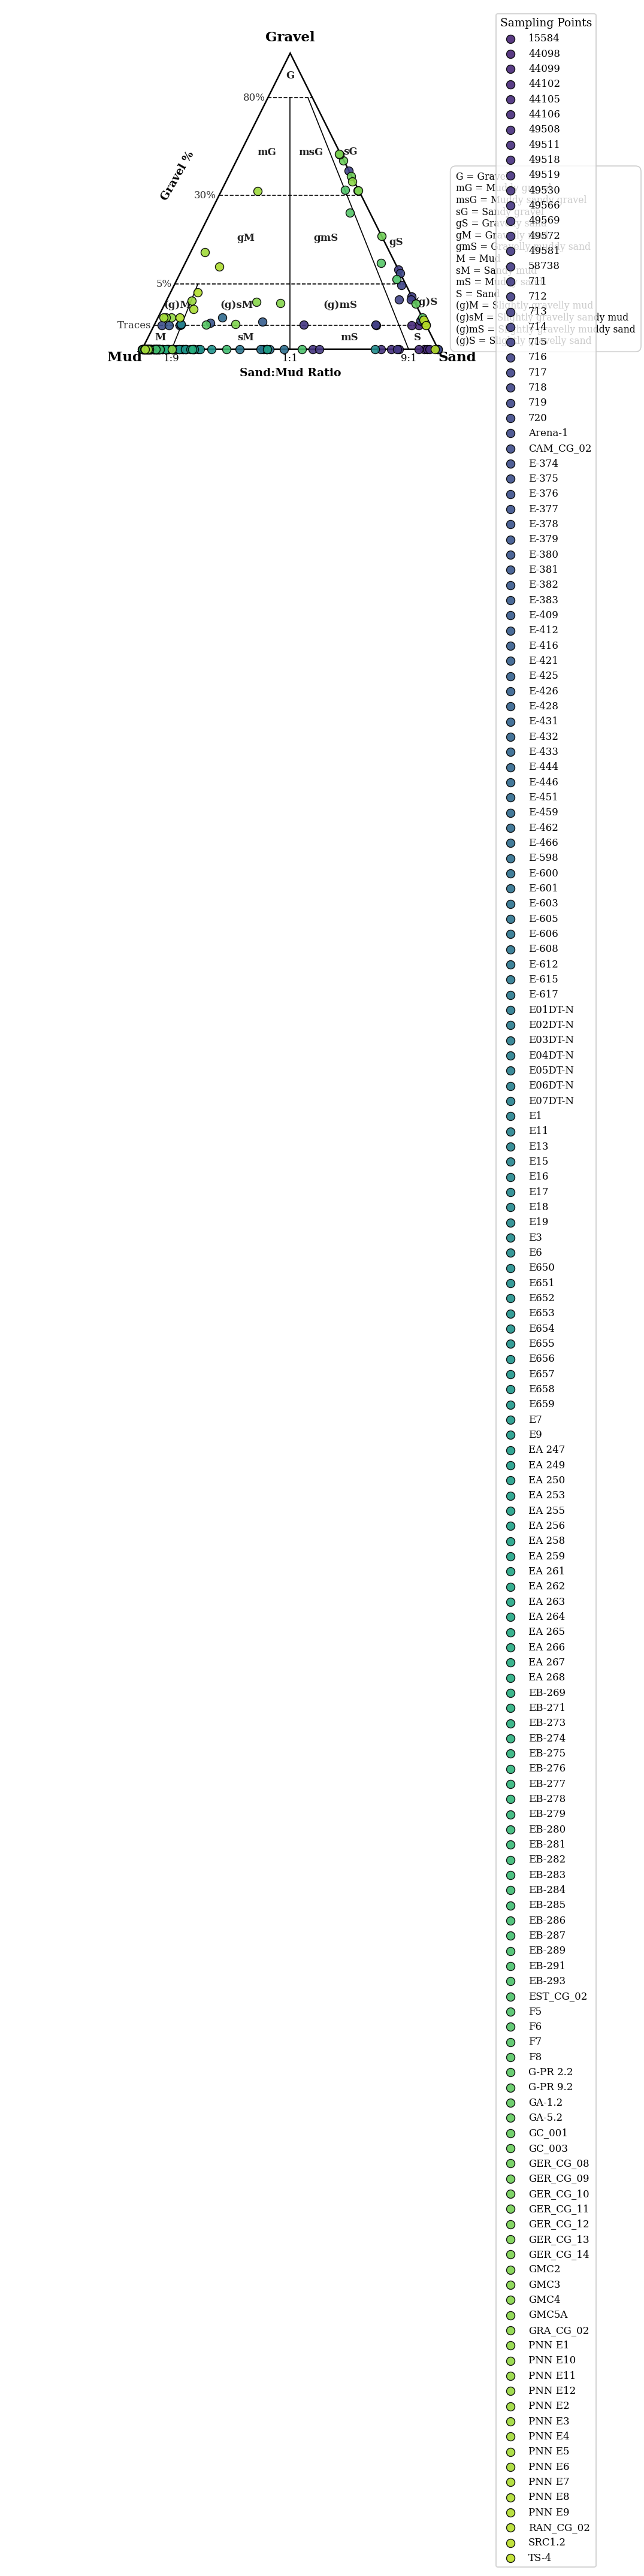

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ==========================================
# CONFIGURACIÓN DE ESTILO PARA PUBLICACIÓN (PAPER)
# ==========================================
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['DejaVu Serif', 'Times New Roman', 'Liberation Serif']
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['figure.dpi'] = 150  # Mayor resolución

# ==============================
# 1. LIMPIEZA DE COLUMNAS
# ==============================
df.columns = df.columns.str.strip()

col_color = 'PUNTOS'  # ← Agrupamiento por PUNTOS
cols_req = ['%_GRAVEL', '%_SAND', '%_MUD', col_color]
faltantes = [c for c in cols_req if c not in df.columns]

if faltantes:
    raise ValueError(f"Missing columns: {faltantes}\nAvailable columns: {list(df.columns)}")

# Convertir a numérico solo las columnas granulométricas
for col in ['%_GRAVEL', '%_SAND', '%_MUD']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Limpieza de texto para la columna de PUNTOS
df[col_color] = df[col_color].astype(str).str.strip()

df = df.dropna(subset=cols_req)

# Normalizar a 100%
df[['%_GRAVEL', '%_SAND', '%_MUD']] = df[['%_GRAVEL', '%_SAND', '%_MUD']].div(
    df[['%_GRAVEL', '%_SAND', '%_MUD']].sum(axis=1), axis=0
) * 100


# ==============================
# 2. FUNCIONES
# ==============================
def to_y(val):
    if val <= 0.01:
        return (val / 0.01) * 8
    elif val <= 5:
        return 8 + (val - 0.01) * (22 - 8) / (5 - 0.01)
    elif val <= 30:
        return 22 + (val - 5) * (52 - 22) / (30 - 5)
    elif val <= 80:
        return 52 + (val - 30) * (85 - 52) / (80 - 30)
    else:
        return 85 + (val - 80) * (100 - 85) / (100 - 80)


def ternary_to_xy(gravel, sand, mud):
    y = to_y(gravel)
    ancho = 100 * (1 - y / 100)

    ratio = 0 if (sand + mud) == 0 else sand / (sand + mud)
    x = (100 - ancho) / 2 + ratio * ancho

    return x, y


# ==============================
# 3. FUNCIÓN PRINCIPAL
# ==============================
def draw_folk_with_data(df):

    fig, ax = plt.subplots(figsize=(8.5, 6))
    h_tri = 100

    # --- Triángulo base ---
    ax.add_patch(patches.Polygon(
        [[0, 0], [50, h_tri], [100, 0]],
        closed=True,
        facecolor='none',  # Fondo transparente estilo paper
        edgecolor='black',
        linewidth=1.2
    ))

    # --- Líneas horizontales ---
    niveles = [0.01, 5, 30, 80]
    labels = {0.01: 'Traces', 5: '5%', 30: '30%', 80: '80%'}

    for n in niveles:
        y_c = to_y(n)
        ancho = 100 * (1 - y_c/h_tri)
        x_s, x_e = (100 - ancho)/2, 100 - (100 - ancho)/2

        ax.plot([x_s, x_e], [y_c, y_c], color='black', linewidth=0.8, linestyle='--')

        if n in labels:
            ax.text(x_s - 1, y_c, labels[n],
                    ha='right', va='center', fontsize=8, color='#333333')

    # --- Líneas de ratio ---
    def get_x_at_y(x_base, y_target):
        return x_base + (50 - x_base) * (y_target / h_tri)

    ax.plot([10, get_x_at_y(10, to_y(5))], [0, to_y(5)], color='black', linewidth=0.8)
    for r in [50, 90]:
        ax.plot([r, get_x_at_y(r, to_y(80))], [0, to_y(80)], color='black', linewidth=0.8)

    # --- Texto interno (SIGLAS) ---
    s = {'ha': 'center', 'va': 'center', 'fontsize': 8, 'weight': 'bold', 'color': '#222222'}

    ax.text(50, to_y(90), "G", **s)
    ax.text(42, to_y(52), "mG", **s)
    ax.text(57, to_y(52), "msG", **s)
    ax.text(35, to_y(18), "gM", **s)
    ax.text(62, to_y(18), "gmS", **s)
    ax.text(68, to_y(51), "sG", ha='left', fontsize=8, weight='bold', color='#222222')
    ax.text(83.5, to_y(16), "gS", ha='left', fontsize=8, weight='bold', color='#222222')

    y_sg_text = to_y(2.5)
    ax.text(12, y_sg_text, "(g)M", **s)
    ax.text(32, y_sg_text, "(g)sM", **s)
    ax.text(67, y_sg_text, "(g)mS", **s)
    ax.text(92, y_sg_text, "(g)S", ha='left', fontsize=8, weight='bold', color='#222222')

    ax.text(6, 4, "M", **s)
    ax.text(35, 4, "sM", **s)
    ax.text(70, 4, "mS", **s)
    ax.text(93, 4, "S", **s)

    # --- Ejes ---
    ax.text(50, 104, 'Gravel', ha='center', weight='bold', fontsize=11)
    ax.text(12, to_y(40), 'Gravel %', weight='bold', fontsize=9, rotation=60, ha='center', va='center')
    ax.text(0, -4, 'Mud', ha='right', weight='bold', fontsize=11)
    ax.text(100, -4, 'Sand', ha='left', weight='bold', fontsize=11)
    ax.text(50, -9, 'Sand:Mud Ratio', ha='center', weight='bold', fontsize=9)

    for r, lab in zip([10, 50, 90], ['1:9', '1:1', '9:1']):
        ax.text(r, -4, lab, ha='center', fontsize=8)

    # ==============================
    # 4. COLORES POR PUNTO
    # ==============================
    puntos_lista = sorted(df[col_color].unique())
    cmap = plt.get_cmap('viridis')

    color_map = {
        punto: cmap(i)
        for punto, i in zip(puntos_lista, np.linspace(0.1, 0.9, len(puntos_lista)))
    }

    # ==============================
    # 5. PLOT POR GRUPOS
    # ==============================
    for punto in puntos_lista:

        df_sub = df[df[col_color] == punto]

        if df_sub.empty:
            continue

        color = color_map[punto]

        x_vals = []
        y_vals = []

        for _, row in df_sub.iterrows():
            x, y = ternary_to_xy(
                row['%_GRAVEL'],
                row['%_SAND'],
                row['%_MUD']
            )
            x_vals.append(x)
            y_vals.append(y)

        ax.scatter(
            x_vals, y_vals,
            s=45,
            color=color,
            edgecolor='black',
            linewidths=0.7,
            label=f'{punto}',
            alpha=0.9,
            zorder=5
        )

    # --- Ajustes de Límites ---
    ax.set_xlim(-45, 155)
    ax.set_ylim(-15, 115)
    ax.set_aspect('equal')
    ax.axis('off')

    # Leyenda principal
    ax.legend(title="Sampling Points", loc='upper right', frameon=True,
              facecolor='white', edgecolor='#cccccc', fontsize=8, title_fontsize=9)

    # ==============================
    # 6. LEYENDA DE SIGLAS (Folk Nomenclature)
    # ==============================
    leyenda_texto = (
        "G = Gravel\n"
        "mG = Muddy gravel\n"
        "msG = Muddy sandy gravel\n"
        "sG = Sandy gravel\n"
        "gS = Gravelly sand\n"
        "gM = Gravelly mud\n"
        "gmS = Gravelly muddy sand\n"
        "M = Mud\n"
        "sM = Sandy mud\n"
        "mS = Muddy sand\n"
        "S = Sand\n"
        "(g)M = Slightly gravelly mud\n"
        "(g)sM = Slightly gravelly sandy mud\n"
        "(g)mS = Slightly gravelly muddy sand\n"
        "(g)S = Slightly gravelly sand"
    )

    ax.text(
        106, 60,
        leyenda_texto,
        fontsize=7.5,
        va='top',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='white', alpha=0.95, edgecolor='#cccccc', linewidth=0.8)
    )

    plt.tight_layout()
    plt.show()


# ==============================
# 6. EJECUCIÓN
# ==============================
draw_folk_with_data(df)

In [ ]:
import pandas as pd
import numpy as np

# 1. Cargar el archivo de Excel original
nombre_archivo = 'BASE _DATOS_COMPILADA.xlsx'
df_original = pd.read_excel(nombre_archivo)

# Crear copias temporales para cálculo y exportación
df_export = df_original.copy()
df_calc = df_original.rename(columns={
    'Gravas_porc': '%_GRAVEL',
    'Arena_porc': '%_SAND',
    'Lodo_Total': '%_MUD'
})

# Convertir a numérico y normalizar a 100%
granulo_cols = ['%_GRAVEL', '%_SAND', '%_MUD']
df_calc[granulo_cols] = df_calc[granulo_cols].apply(pd.to_numeric, errors='coerce')
suma = df_calc[granulo_cols].sum(axis=1).replace(0, 100)

df_calc['G_norm'] = (df_calc['%_GRAVEL'] / suma) * 100
df_calc['S_norm'] = (df_calc['%_SAND'] / suma) * 100
df_calc['M_norm'] = (df_calc['%_MUD'] / suma) * 100

# 2. Función Matemática de Clasificación (Folk, 1954/1974)
def classify_folk(row):
    g, s, m = row['G_norm'], row['S_norm'], row['M_norm']
    if pd.isna(g) or pd.isna(s) or pd.isna(m):
        return None, None

    ratio_sm = s / (s + m) if (s + m) > 0 else 0

    if g >= 80:
        return "G", "Gravel"
    elif 30 <= g < 80:
        if ratio_sm < 0.1: return "mG", "Muddy gravel"
        elif ratio_sm < 0.5: return "msG", "Muddy sandy gravel"
        else: return "sG", "Sandy gravel"
    elif 5 <= g < 30:
        if ratio_sm < 0.1: return "gM", "Gravelly mud"
        elif ratio_sm < 0.5: return "gmS", "Gravelly muddy sand"
        else: return "gS", "Gravelly sand"
    elif 0.01 <= g < 5:
        if ratio_sm < 0.1: return "(g)M", "Slightly gravelly mud"
        elif ratio_sm < 0.5: return "(g)sM", "Slightly gravelly sandy mud"
        elif ratio_sm < 0.9: return "(g)mS", "Slightly gravelly muddy sand"
        else: return "(g)S", "Slightly gravelly sand"
    else:
        if ratio_sm < 0.1: return "M", "Mud"
        elif ratio_sm < 0.5: return "sM", "Sandy mud"
        elif ratio_sm < 0.9: return "mS", "Muddy sand"
        else: return "S", "Sand"

# 3. Procesar y Exportar
resultados = df_calc.apply(classify_folk, axis=1)
df_export['Folk_Code'] = [r[0] for r in resultados]
df_export['Folk_Name'] = [r[1] for r in resultados]

# Guardar resultado final en Colab
df_export.to_excel('BASE_DATOS_CLASIFICADA_FOLK.xlsx', index=False)
print("¡Clasificación completada y archivo listo para descargar!")

¡Clasificación completada y archivo listo para descargar!
